In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from wordcloud import WordCloud

In [2]:
from google.colab import files
uploaded = files.upload()

Saving chatgpt_reviews.xlsx to chatgpt_reviews.xlsx


In [3]:
import pandas as pd
df = pd.read_excel('chatgpt_reviews.xlsx')
print(df.head())
print(df.shape)

                              Review Id  \
0  6fb93778-651a-4ad1-b5ed-67dd0bd35aac   
1  81caeefd-3a28-4601-a898-72897ac906f5   
2  452af49e-1d8b-4b68-b1ac-a94c64cb1dd5   
3  372a4096-ee6a-4b94-b046-cef0b646c965   
4  b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da   

                                              Review  Ratings  \
0                                               good        5   
1                                               good        5   
2                                           nice app        5   
3                                           nice, ig        5   
4  this is a great app, the bot is so accurate to...        5   

          Review Date  
0 2024-08-23 19:30:05  
1 2024-08-23 19:28:18  
2 2024-08-23 19:22:59  
3 2024-08-23 19:20:50  
4 2024-08-23 19:20:39  
(196727, 4)


In [4]:
df['Ratings'] = pd.to_numeric(df['Ratings'], errors='coerce')
df['Review Date'] = pd.to_datetime(df['Review Date'], errors='coerce')
df = df.dropna(subset=['Review'])

In [5]:
def get_polarity(text):
    return TextBlob(str(text)).sentiment.polarity

def get_subjectivity(text):
    return TextBlob(str(text)).sentiment.subjectivity

df['polarity'] = df['Review'].apply(get_polarity)
df['subjectivity'] = df['Review'].apply(get_subjectivity)

def get_sentiment(p):
    if p > 0.1:
        return 'Positive'
    elif p < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['polarity'].apply(get_sentiment)
print(df[['Review','polarity','Sentiment']].head())

                                              Review  polarity Sentiment
0                                               good    0.7000  Positive
1                                               good    0.7000  Positive
2                                           nice app    0.6000  Positive
3                                           nice, ig    0.6000  Positive
4  this is a great app, the bot is so accurate to...    0.4125  Positive


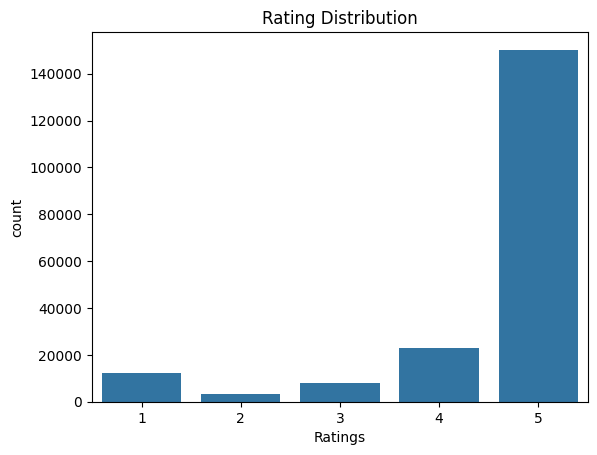

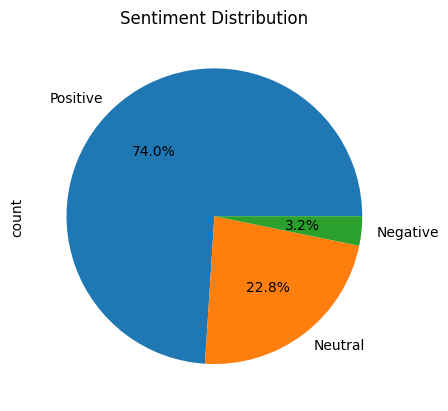

In [6]:
sns.countplot(x='Ratings', data=df)
plt.title('Rating Distribution')
plt.show()

df['Sentiment'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title('Sentiment Distribution')
plt.show()

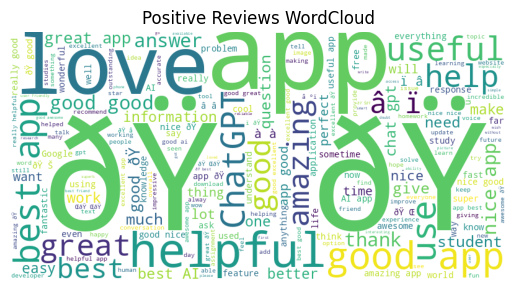

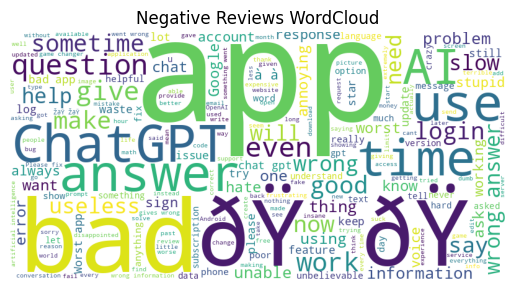

In [7]:
# Positive Reviews WordCloud
positive_text = " ".join(df[df['Sentiment']=='Positive']['Review'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(positive_text)
plt.imshow(wordcloud)
plt.axis('off')
plt.title('Positive Reviews WordCloud')
plt.show()

# Negative Reviews WordCloud
negative_text = " ".join(df[df['Sentiment']=='Negative']['Review'])
if len(negative_text) > 0:
    wordcloud2 = WordCloud(width=800, height=400, background_color='white').generate(negative_text)
    plt.imshow(wordcloud2)
    plt.axis('off')
    plt.title('Negative Reviews WordCloud')
    plt.show()